# Trabajo 3 de MINION en Khipu

Latencia, continuidad y fallas con TREC-COVID, comparable por montaje nominal con FiQA v4. Esta ejecución usa corpus completo y no cambia α=0,85. La relevancia se evalúa en el Trabajo 1; aquí se miden tiempos y rutas de respuesta.

## Qué queremos aprender

Al aumentar la tasa de llegada, observamos la cola de latencia y las rutas de respaldo. Al inyectar fallas, comprobamos si la respuesta sigue entregando tres documentos dentro de 2500 ms. F3H y F3NH cambian la política de hedging con iguales llegadas y asignación determinista de demoras. Las demoras efectivas pueden diferir por respaldos antes del reranker; se audita esa exposición sin afirmar aislamiento causal perfecto. Las repeticiones describen la variación del montaje: mediana y rango no son intervalos de confianza.

In [1]:
from pathlib import Path
import json,sys
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT))
from analyze_v4 import Run
run=Run(ROOT)
print('Job experimental:',run.meta['slurm_job_id'],'| nodo:',run.meta['node'])
print('Job de análisis:',__import__('os').environ.get('SLURM_JOB_ID'))
print('Referencia externa de carga (NO capacidad TREC):',run.cal['C_qps'],'QPS | hedge:',run.cal['hedge_threshold_ms'],'ms')

Job experimental: 63919 | nodo: ds001
Job de análisis: 63913
Referencia externa de carga (NO capacidad TREC): 8 QPS | hedge: 154.424 ms


## Montaje y comparabilidad

La referencia es FiQA v4, job 63828. Se mantienen código, configuración, α, Python, librerías, nodo ds001/A6000, un shard, 4 CPU, 32 GB, 3 repeticiones, 180 s por condición y 30 s de descarte. El protocolo original de capacidad falla en TREC. El ensayo complementario usa las mismas cargas absolutas de FiQA (2/4/6/8 QPS), conservando plazos y código; no constituye una comparación a C propia de TREC. La GPU es compartida: no se controla la misma contención que en la referencia. La revisión exacta de MiniLM no fue registrada por FiQA; se documenta la nueva revisión, sin afirmar una comprobación retrospectiva de pesos.

In [2]:
comparison=json.loads((ROOT/'comparability_final.json').read_text())
display(pd.Series(comparison['checks']).to_frame('verificado'))
print('Python benchmark:',run.meta['python'].split()[0])
display(pd.Series(run.meta['libraries']).to_frame('versión'))
print('Hardware registrado:')
print(run.meta['nvidia_smi'])

,verificado
same_source,True
same_python,True
same_libraries,True
same_node,True
same_gpu_model,True
same_frozen_config,True
same_alpha,True
same_threads,True
same_reps,True
same_cond_seconds,True


Python benchmark: 3.11.11


,versión
torch,2.15.0
transformers,5.23.0
sentence-transformers,6.3.0
faiss-cpu,1.16.0
bm25s,0.3.16
PyStemmer,3.1.0
numpy,2.4.6


Hardware registrado:
Wed Nov 18 20:23:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.04              KMD Version: 610.57.04     CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A6000               Off |   00000000:99:00.0 Off |                  Off |
| 60%   83C    P2            253W /  300W |   40737MiB /  49140MiB |    100%      Default |
|                                         |                        |                  N/A |
+--------------------------

## Flujo de una solicitud

El generador Poisson no espera la solicitud anterior. La latencia se cuenta desde el instante programado, incluyendo espera. BM25 y BGE corren en paralelo; se unen sus top 10, se completan ambos puntajes y se normaliza min-max por consulta. La fusión α=0,85 alimenta el reranker y sus dos réplicas comparten la A6000. Si una etapa falla o vence su plazo, se devuelve la ruta de respaldo correspondiente.

```text
Poisson open-loop → BM25 y BGE en paralelo → unión y fusión
 → reranker A (hedge B si aplica) → respuesta o respaldo
```

## Datos y condiciones

Se usan 171.332 documentos y las 50 consultas test. Las consultas de calibración son títulos de 1000 documentos elegidos con semilla 42; se envían 500 en la calibración a 1 QPS. FiQA usa consultas train como calibración. El test no se utiliza para elegir α ni umbrales de relevancia.

In [3]:
display(Markdown((ROOT/'PLAN_EXPERIMENTAL.md').read_text()))
print('Argumentos ejecutados:')
display(pd.Series(run.meta['args']).to_frame('valor'))

# Plan experimental comparable con FiQA v4

## Preguntas

1. ¿Qué relevancia producen BM25, BGE, la fusión y el reranking? La responde el Trabajo 1 con qrels y consultas test, después de fijar α en desarrollo.
2. ¿Qué ocurre con la cola de latencia al aumentar la carga? La responden los Trabajos 2 y 3 con un generador Poisson open-loop y latencia desde el instante programado.
3. ¿Se entregan tres documentos dentro de 2,5 segundos cuando fallan componentes? Se responde con continuidad y distribución de rutas.
4. ¿El hedging reduce la cola bajo demoras inyectadas con un presupuesto de copias? Se contrasta F3H contra F3NH con las mismas consultas, llegadas y asignación determinista de demoras. La exposición efectiva puede diferir por respaldos previos al reranker, y se audita por solicitud.

## Qué se mantiene fijo

La referencia es el Trabajo 2 de FiQA, job 63828, nodo ds001, RTX A6000 compartida, script v4 con SHA-256 `bb027763a577074373d5c1909467fbac67f8b5484d37696b29e1f697f02f22b7`.

Se conservan el código, α=0,85 y su configuración, Python 3.11.11, las versiones registradas de las librerías, nodo y modelo de GPU, un shard, 4 CPU/hilos, 32 GB de RAM, tres repeticiones, las 13 condiciones, duración de 180 segundos por condición, descarte de 30 segundos, tiempos de espera, política de respaldo y limitador v4 de duplicadas.

Antes de la corrida, `comparability_check.py` verifica automáticamente la huella del código, el contenido de alpha.json, la configuración congelada, Python, las versiones y el modelo de GPU.

## Qué cambia intencionalmente

El corpus y las consultas cambian a TREC-COVID: 171.332 documentos y 50 consultas test. Se conserva texto título + espacio + contenido y el mismo pipeline.

Cada dataset se calibra de nuevo: 500 consultas a 1 QPS, umbral de hedging igual al p95 del reranker, y rampa 1, 2, 4, 8, 16, 32, 64 QPS con 120 segundos por escalón. La fuente de consultas de calibración sigue el código v4: train en FiQA y títulos aleatorios del corpus en TREC-COVID, semilla 42.

La C principal exige al menos 99 % de respuestas reranked y p99 estable, y se limita por el primer escalón fallido. El diagnóstico de capacidad que admite otras rutas se registra por separado. C y el umbral de FiQA no se copian a TREC-COVID.

Los niveles L25–L100 son porcentajes de la C de cada dataset. No necesariamente representan los mismos QPS absolutos. Deben mostrarse ambas cifras al comparar.

## Condiciones y significado

| Condición | Intervención | Qué permite observar |
|---|---|---|
| L25, L50, L75, L100 | 25, 50, 75 y 100 % de C | Latencia bajo carga y uso de respaldos |
| NORERANK | No invoca el reranker | Referencia temporal de fusión sola |
| NOHEDGE | Reranker sin copias | Costo del sistema completo sin hedging |
| F1 | Ambas réplicas del reranker fallan | Respaldo fusionado por error |
| F2 | Ambas réplicas se demoran 1500 ms | Respaldo por vencimiento de plazo |
| F3H | Demora de 800 ms en 5 % de solicitudes, con hedging | Política de duplicación |
| F3NH | Misma asignación de demoras y llegadas, sin hedging | Control pareado de F3H |
| F4 | Falla semántica | Respaldo léxico |
| F5 | Falla léxica | Respaldo semántico |
| F6 | Fallan ambas rutas de recuperación | Error controlado; no se esperan tres resultados |

## Qué se mide y cómo se resume

Se guardan todas las solicitudes. Para estadísticas finales se excluyen las programadas antes de 30 segundos. p50, p95 y p99 se calculan sobre respuestas con tres documentos, con el método de rango ceil(q × N). La continuidad usa como denominador todas las solicitudes medidas y exige tres documentos y latencia menor o igual a 2500 ms.

Se muestran los tres valores por condición, su mediana y rango. Con tres repeticiones, ese rango es descriptivo y no debe llamarse intervalo de confianza. Los IC del Trabajo 1 y de los complementarios provienen de 10.000 remuestreos de consultas; responden otra pregunta.

El porcentaje de duplicadas es copias enviadas dividido entre invocaciones originales del reranker, usando el mismo descarte de calentamiento. Se muestran los porcentajes de cada ruta: continuidad de 100 % no significa que todas las consultas hayan completado reranking.

## Límites de comparabilidad que deben mantenerse visibles

ds001 es compartido. La corrida FiQA tenía otros procesos usando la A6000; las condiciones actuales de contención pueden diferir. Se registran nvidia-smi, metadatos y recursos Slurm. Compartir nodo y GPU no equivale a aislamiento ni convierte toda diferencia en un efecto causal del dataset.

La revisión de BGE está fijada. La referencia FiQA registró el nombre de MiniLM pero no su revisión exacta de caché; la nueva corrida conserva la revisión preparada. La comparación de pesos del reranker con el archivo físico usado por la referencia no puede demostrarse solo con sus metadatos.

Las réplicas comparten GPU y máquina y no simulan aislamiento de fallas físicas. Las fallas son inyectadas en el proceso. Relevancia y latencia se estudian en corridas distintas; no debe presentarse una curva de calidad bajo carga como si hubiera sido medida.

## Evidencia que se actualizará

La carpeta consolidada incorporará una serie TREC-COVID/Khipu nueva, sin reemplazar TREC-COVID/Kaggle. Se actualizarán las tablas de latencia y fitness, la comparación FiQA/TREC en ds001, las figuras, un notebook ejecutado, la procedencia, las huellas SHA-256 y el resumen explicativo. Piloto y corridas finales permanecerán separados.

## Incidencia de calibración y análisis complementario a carga fija

El job 63911 conserva el intento exacto del protocolo anterior. En el primer escalón no se alcanzó el 99 % de ruta completa; el programa original se detiene sin fijar C. No se aumenta el plazo léxico, no se reduce el 99 % y no se presenta la continuidad por respaldo como capacidad de reranking.

Para completar el contraste operativo se ejecuta el job 63919 como **análisis complementario a carga absoluta fija**. La referencia se toma de FiQA job 63828, cuyo C ya registrado era 8 QPS. Se aplican a TREC las mismas cargas absolutas 2/4/6/8 QPS, conservando código, recursos, 13 condiciones, tres repeticiones y plazos. La fase `runs` del código original lee un adaptador de entrada: su campo `C_qps=8` es únicamente una escala externa de carga y NO es una capacidad validada de TREC. `capacity_validated=false` y `trec_capacity_qps=null` quedan registrados.

El umbral de hedge de TREC se calcula con los 500 registros de su intento de calibración: p95 de rerank de las solicitudes que completaron esa ruta, siguiendo el mismo cálculo original. `prepare_fixed_load.py` documenta la adaptación y preserva el intento fallido. Los valores de rampa solo quedaron redondeados en stdout porque la fuente original aborta antes de guardar calibration.json. Las 500 solicitudes iniciales sí se guardan completas.

Este contraste responde qué pasa **a los mismos QPS absolutos** en el mismo montaje nominal. No permite comparar L100 como 100 % de la capacidad propia de cada dataset ni afirmar que TREC sostuvo 8 QPS con ≥99 % de reranking. La falla de calibración y las rutas de respaldo forman parte del resultado, y la contención compartida permanece sin controlar.

## Auditoría de exposición a demoras

El código asigna la demora de F3 por semilla 42, repetición e índice de solicitud. La bandera delay_injected solo se activa si se alcanza el reranker. Las consultas y horarios de F3H/F3NH coinciden, pero un timeout léxico puede llevar una de las dos a respaldo antes de aplicar la demora. Se conservan las banderas observadas, se verifica que toda demora aplicada estuviera asignada y se reportan las diferencias por repetición. No se sustituyen esas banderas por las asignadas ni se eliminan consultas; la diferencia de p99 describe las ventanas completas y no aísla causalmente solo el hedge.


Argumentos ejecutados:


,valor
dataset,trec-covid
reps,3
out,results_trec_covid_carga_fija_v4/
data_dir,data
alpha_json,alpha.json
subset,0
cond_seconds,180.0
warmup_seconds,30.0
calib_queries,500
ramp_seconds,120.0


## Calibración separada por dataset

El umbral de hedging es el p95 del reranker medido a 1 QPS. C exige al menos 99 % de respuestas de ruta completa reranked y estabilidad del p99. En v4, la primera falla limita C; el resto de la rampa se conserva como diagnóstico. La calibración original 63911 no pudo fijar C: la primera tasa falló. Los datos de 500 consultas se conservan, pero la fuente original solo dejó la rampa redondeada en el log. El umbral propio de hedging se reutiliza y la carga se fija externamente a partir de FiQA; no se cambia el 99 % ni se declara una capacidad de TREC.

In [4]:
display(pd.DataFrame(run.cal['ramp_log_rounded']))
print('C TREC validada:',run.cal['trec_capacity_qps'])
print('Referencia externa de carga:',run.cal['C_qps'])

,offered_qps,achieved_qps_rounded,p99_first_half_ms_rounded,p99_second_half_ms_rounded,reranked_pct_rounded,passes,passes_any
0,1.0,0.94,425.0,263.0,97.0,False,True
1,2.0,2.02,449.0,324.0,97.0,False,True
2,4.0,4.04,739.0,472.0,95.0,False,True
3,8.0,7.78,1061.0,1491.0,93.0,False,False
4,16.0,16.48,2381.0,2398.0,8.0,False,True
5,32.0,31.11,2376.0,2368.0,12.0,False,False
6,64.0,62.43,1242.0,1287.0,0.0,False,False


C TREC validada: None
Referencia externa de carga: 8


### K1 Calibración

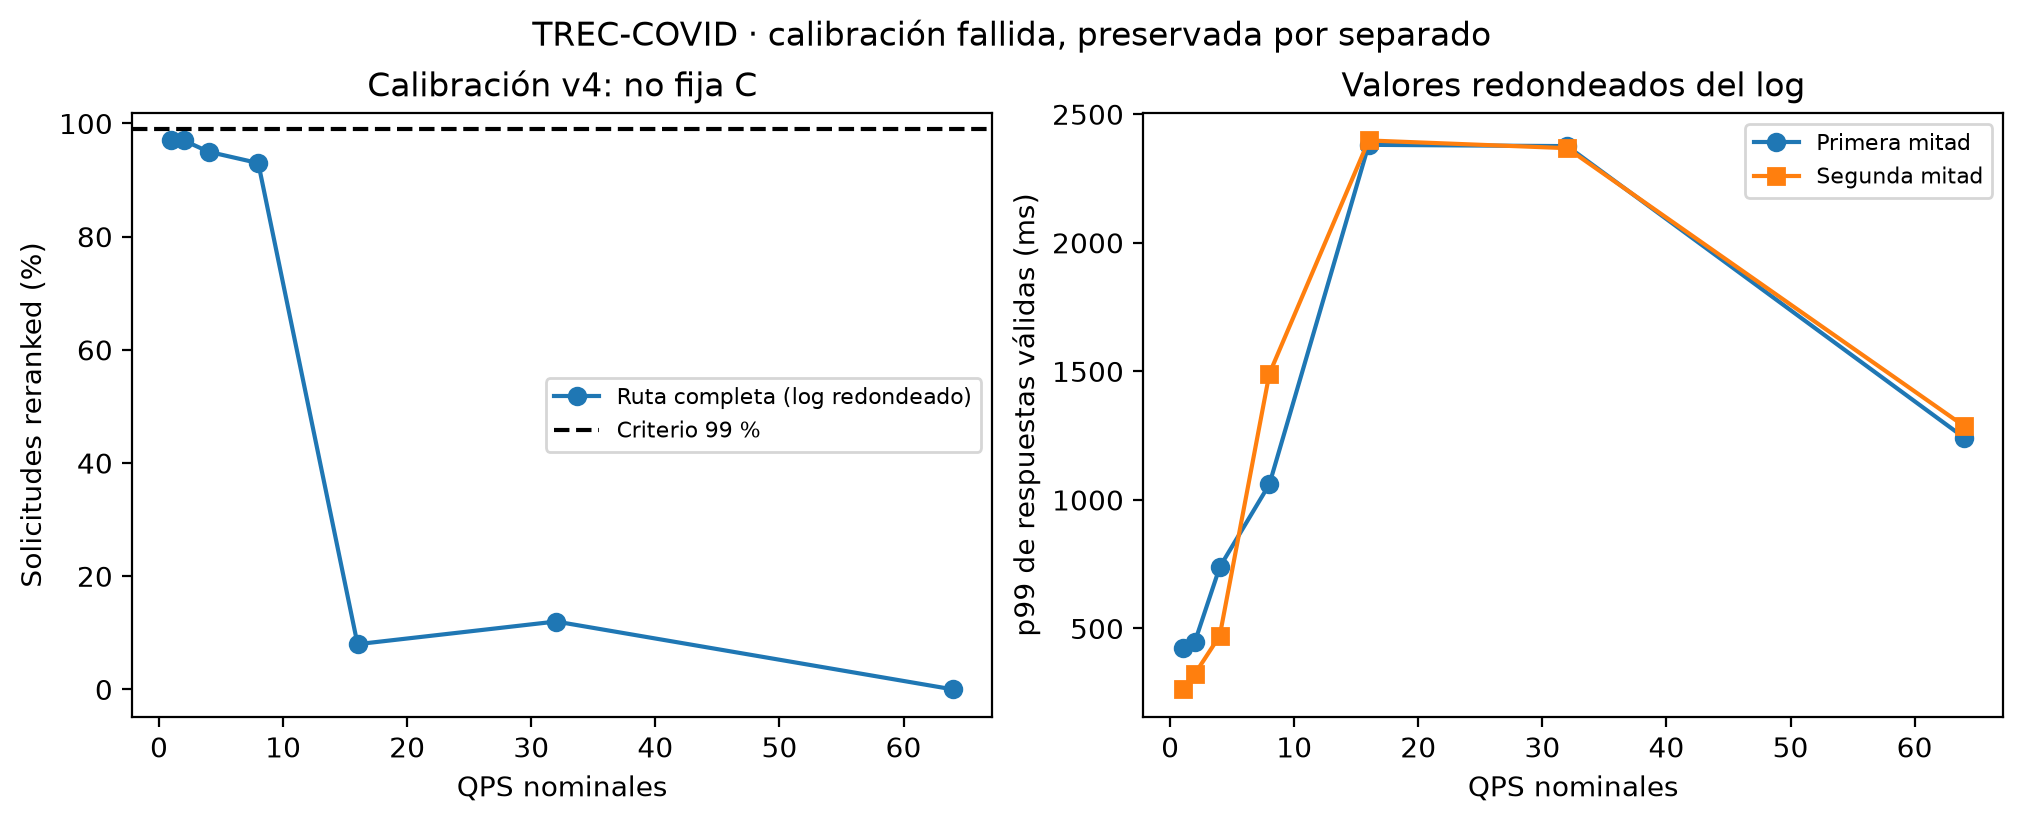

In [5]:
display(Image(filename=str(ROOT/'figs'/'K1_rampa_trec-covid.png')))

El primer escalón falla: no hay C validada en esta grilla. La rampa solo se conserva redondeada en stdout por el código original. El ensayo complementario usa 8 QPS como referencia externa de carga, no como C de TREC.

### K2 Calibración

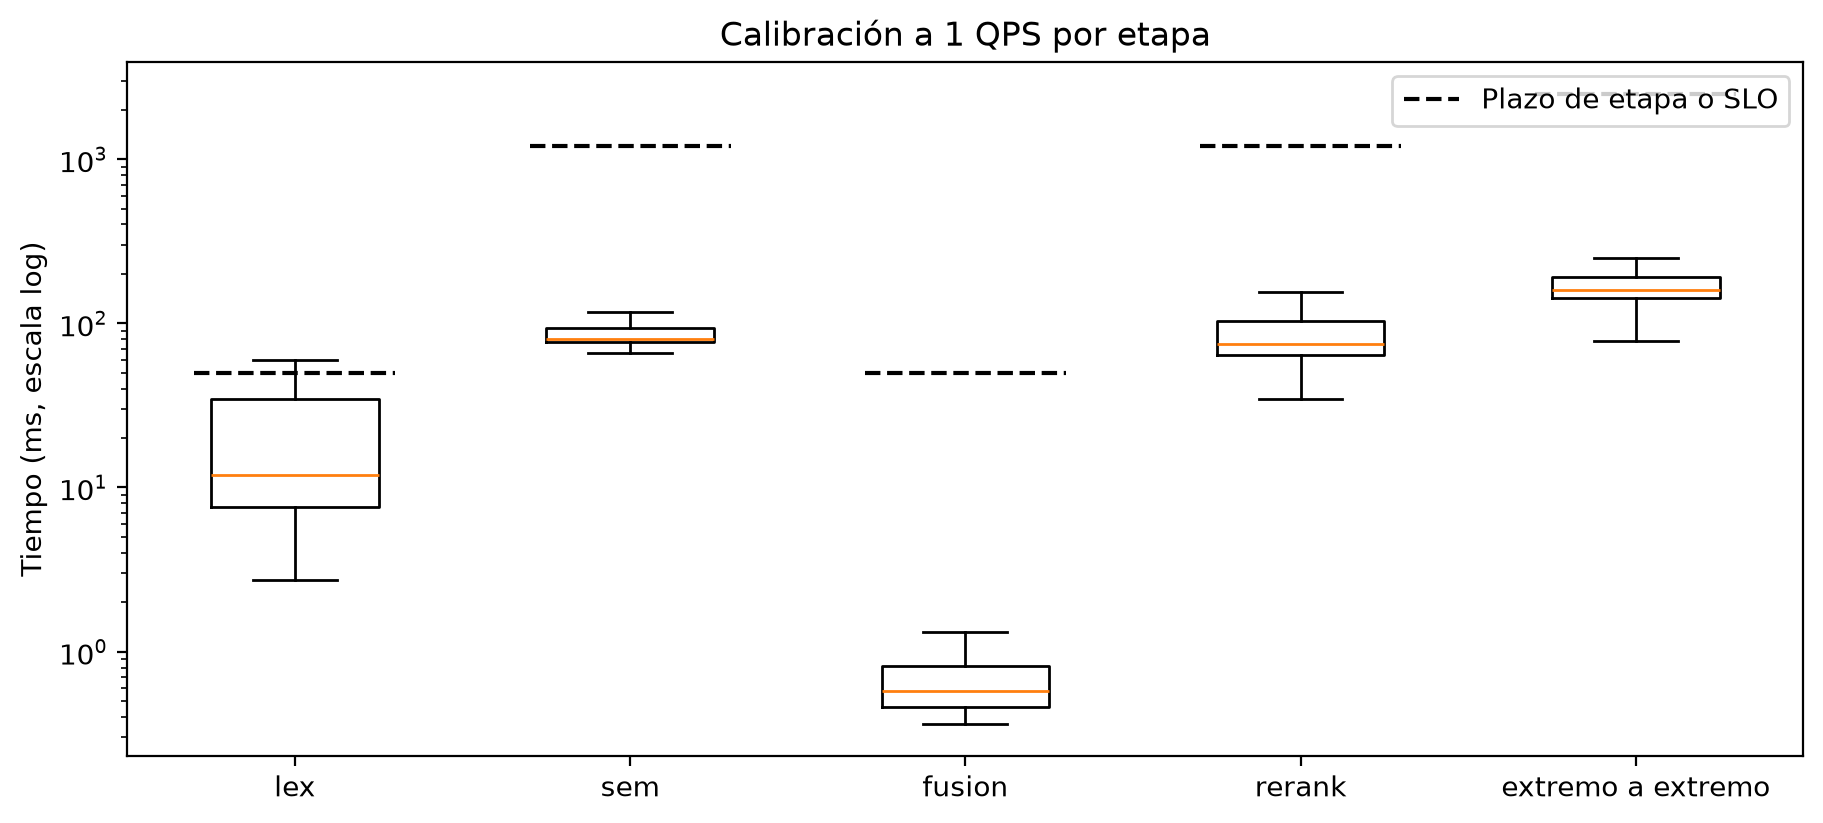

In [6]:
display(Image(filename=str(ROOT/'figs'/'K2_etapas_trec-covid.png')))

Umbral de hedge = p95 de rerank en calibración: 154.424 ms. Las líneas son plazos de respaldo. Se muestran tiempos positivos registrados; en un timeout se mide la espera hasta vencer el plazo, no el tiempo posterior del hilo residual.

## Carga y latencia

L25–L100 son etiquetas heredadas del código: aquí representan 2/4/6/8 QPS, porcentajes de la referencia externa de FiQA, NO de una C validada para TREC. Los percentiles se calculan con ceil(q×N) sobre respuestas de tres documentos. La continuidad incluye todas las solicitudes medidas. Una latencia válida puede provenir de respaldo, por lo que también se debe mirar la distribución de rutas.

In [7]:
display(run.aggregate())
print('Resultados individuales de las tres repeticiones:')
display(run.summary[['rep','condition','offered_qps','n_sent','p99_ms','continuity_pct','pct_dup']])

,condition,repetitions,nominal_qps,requests,p50_ms_median,p50_ms_min,p50_ms_max,p95_ms_median,p95_ms_min,p95_ms_max,p99_ms_median,p99_ms_min,p99_ms_max,continuity_pct_median,continuity_pct_min,continuity_pct_max,pct_dup_median,pct_dup_min,pct_dup_max
0,L25,3,2.0,880,186.572,179.458,203.074,335.978,324.304,470.140,560.392,555.971,721.752,100.0,100.000,100.0,7.718,7.605,9.220
1,L50,3,4.0,1731,243.233,212.658,262.257,588.425,495.958,671.113,974.827,743.587,992.754,100.0,100.000,100.0,9.428,8.982,9.582
2,L75,3,6.0,2651,374.291,296.388,465.236,1315.294,838.428,1382.792,1527.138,1125.473,1617.307,100.0,100.000,100.0,9.725,9.658,9.751
3,L100,3,8.0,3590,771.503,506.166,1208.122,1515.392,1429.083,1764.375,1745.818,1728.866,2067.905,100.0,99.917,100.0,9.912,9.904,9.915
4,NORERANK,3,8.0,3590,121.753,120.335,124.959,231.692,221.689,231.743,297.188,251.153,315.829,100.0,100.000,100.0,0.000,0.000,0.000
5,NOHEDGE,3,8.0,3590,575.229,404.996,1281.453,1487.553,1367.906,1556.901,1698.704,1696.292,1857.938,100.0,100.000,100.0,0.000,0.000,0.000
6,F1,3,6.0,2651,111.040,103.659,111.711,194.688,188.675,197.002,233.912,223.089,283.552,100.0,100.000,100.0,9.896,9.804,9.926
7,F2,3,6.0,2651,1307.235,1303.290,1313.002,1388.516,1386.782,1390.314,1438.326,1426.781,1439.867,100.0,100.000,100.0,9.773,9.762,9.882
8,F3H,3,6.0,2651,351.228,292.014,468.951,1114.728,1085.879,1302.828,1411.136,1319.865,1490.621,100.0,100.000,100.0,9.725,9.711,9.729
9,F3NH,3,6.0,2651,356.594,266.220,370.174,1067.544,973.568,1216.496,1324.644,1232.879,1484.724,100.0,100.000,100.0,0.000,0.000,0.000


Resultados individuales de las tres repeticiones:


,rep,condition,offered_qps,n_sent,p99_ms,continuity_pct,pct_dup
0,1,L25,2.0,275,555.971,100.000,7.605
1,1,L50,4.0,535,743.587,100.000,8.982
2,1,L75,6.0,855,1125.473,100.000,9.658
3,1,L100,8.0,1187,1745.818,100.000,9.912
4,1,NORERANK,8.0,1187,297.188,100.000,0.000
5,1,NOHEDGE,8.0,1187,1696.292,100.000,0.000
6,1,F1,6.0,855,233.912,100.000,9.926
7,1,F2,6.0,855,1426.781,100.000,9.762
8,1,F3H,6.0,855,1319.865,100.000,9.729
9,1,F3NH,6.0,855,1232.879,100.000,0.000


### K3 Carga

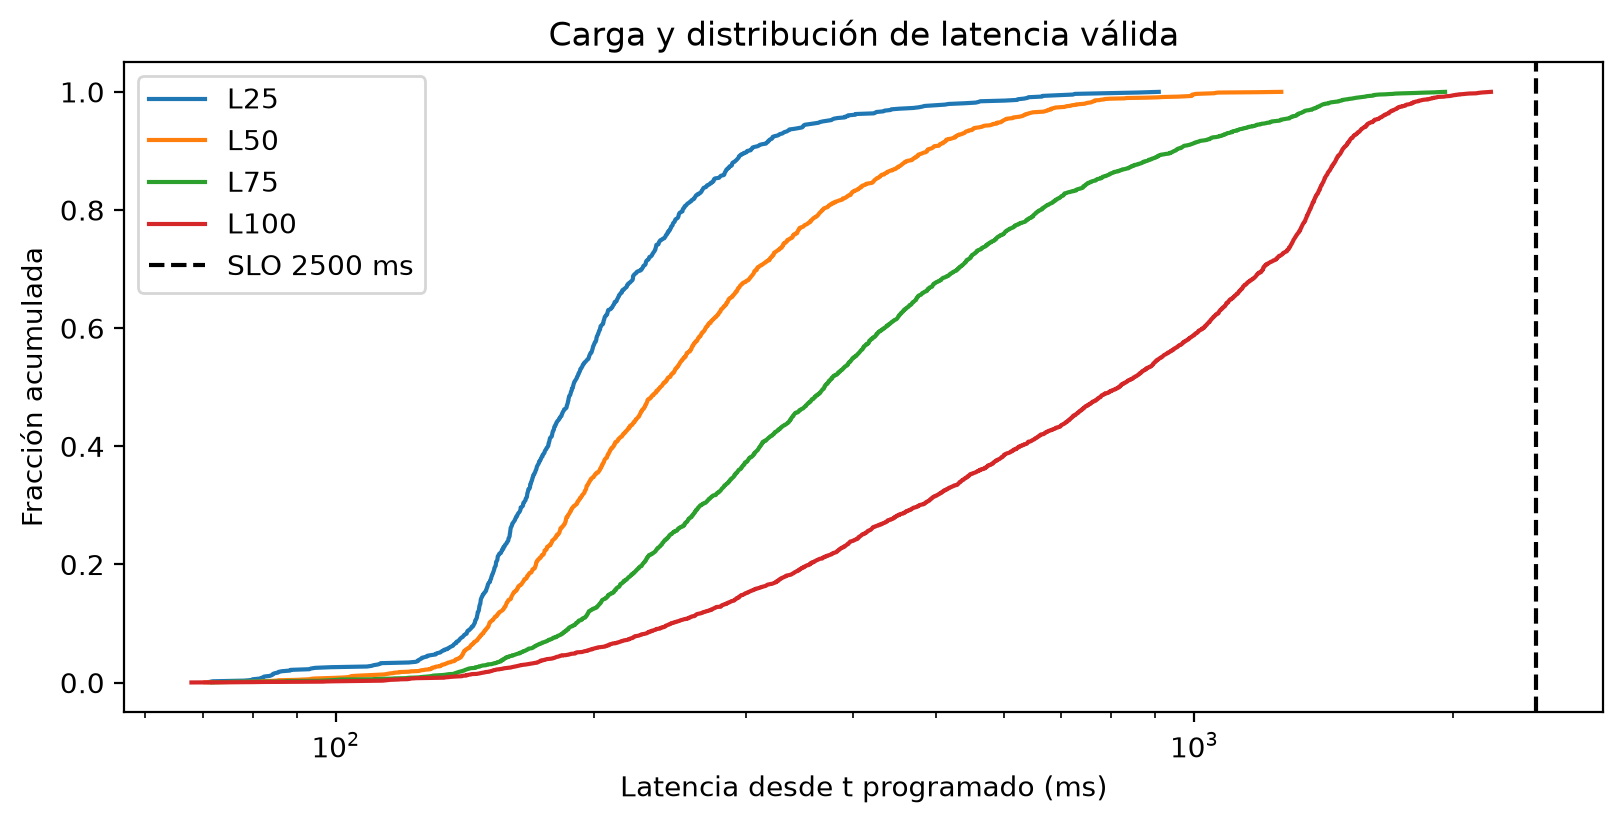

In [8]:
display(Image(filename=str(ROOT/'figs'/'K3_ecdf_carga_trec-covid.png')))

Las ECDF reúnen respuestas válidas de las tres repeticiones después del calentamiento. La continuidad, cuyo denominador incluye errores, se muestra aparte.

### K4 Carga

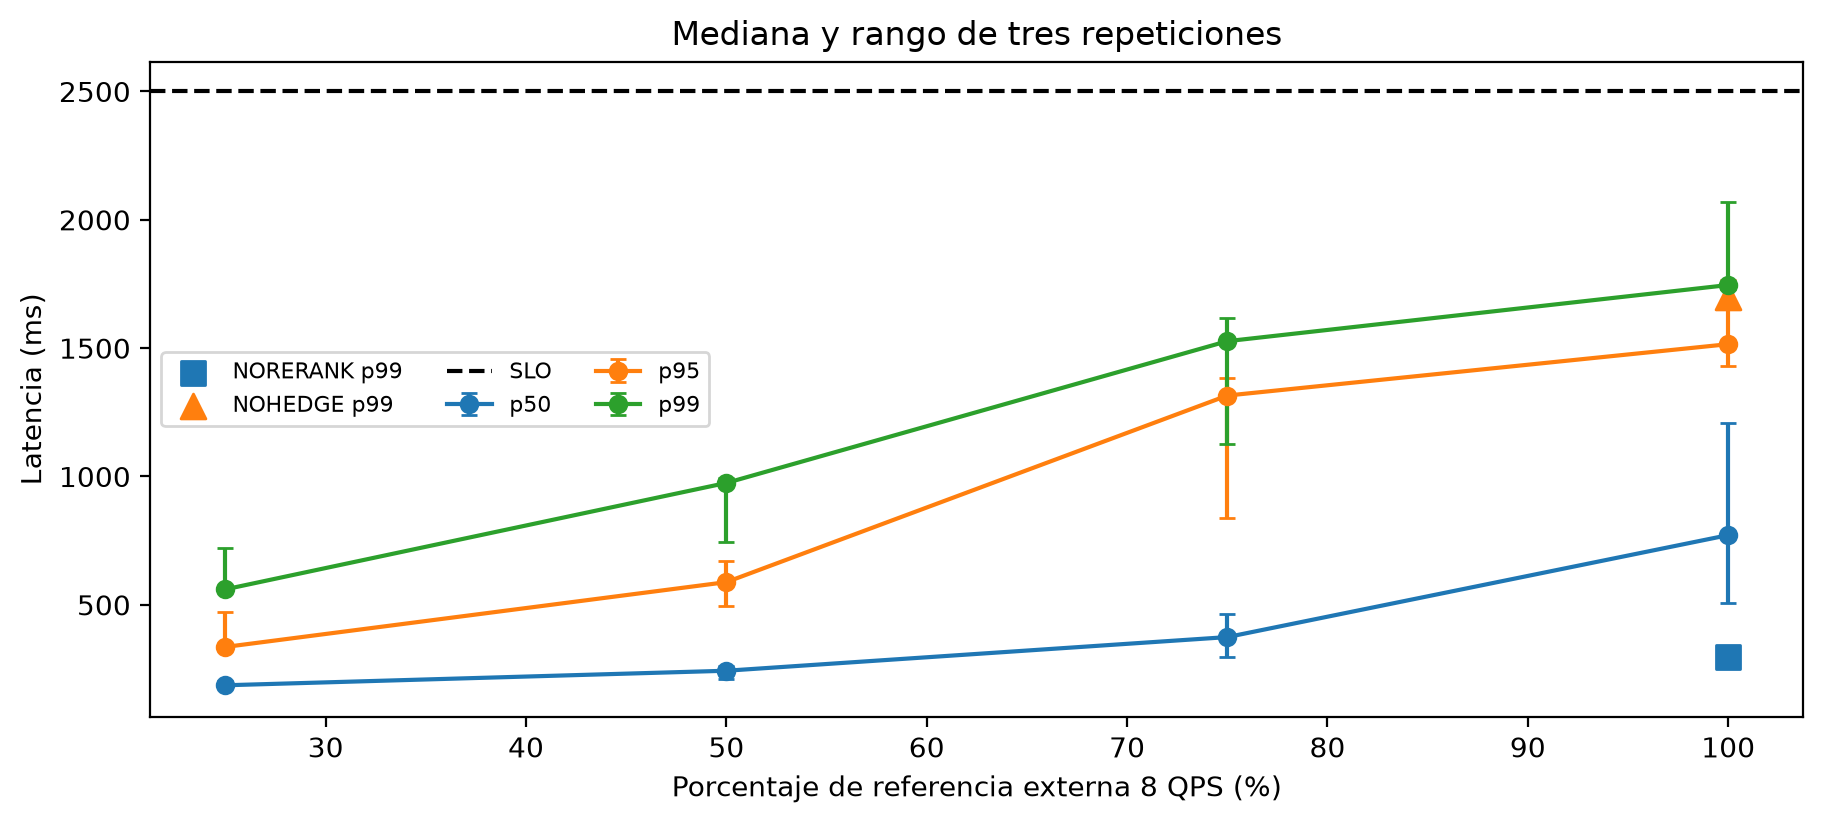

In [9]:
display(Image(filename=str(ROOT/'figs'/'K4_percentiles_carga_trec-covid.png')))

En L100, p99 mediano = 1745.8 ms. Las barras son rangos mínimo–máximo, no intervalos de confianza.

### K5 Carga

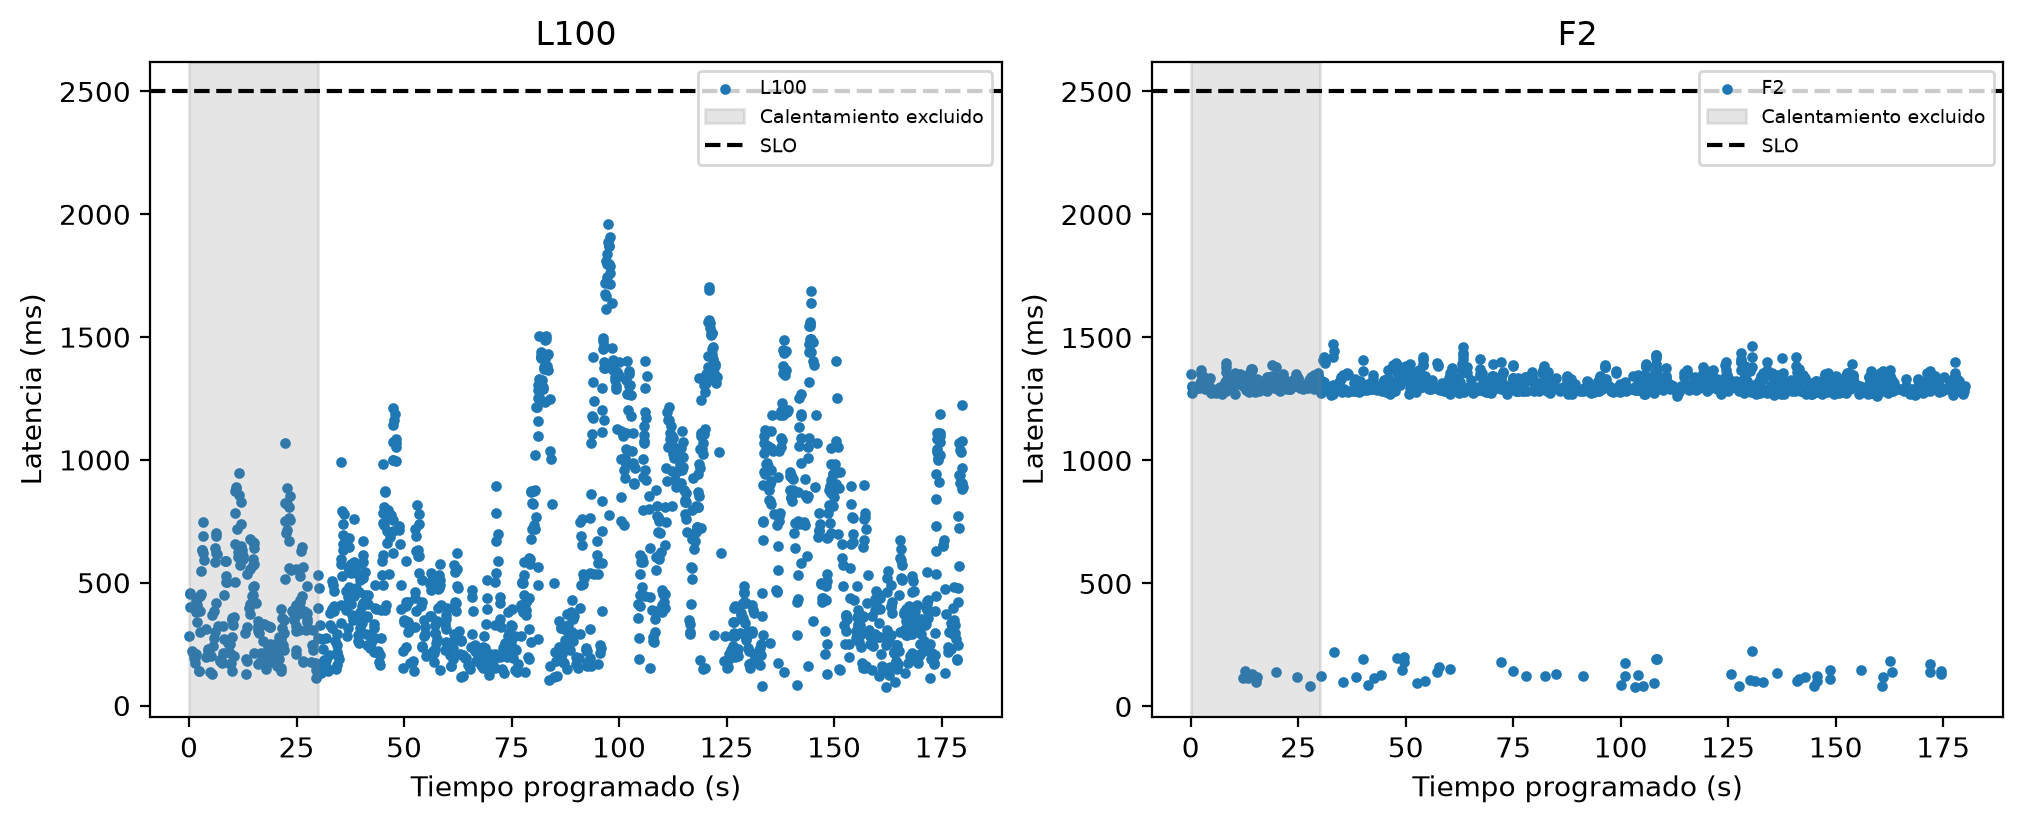

In [10]:
display(Image(filename=str(ROOT/'figs'/'K5_serie_tiempo_trec-covid.png')))

Se conserva el calentamiento en esta visualización y se sombrea, aunque se excluye de los estadísticos. F2 fuerza vencimiento del plazo del reranker.

## Fallas y rutas de respuesta

NORERANK omite el modelo y es una referencia de costo temporal. F1/F2 sí intentan invocarlo y activan respaldo por error o timeout. F4/F5 conservan la ruta de recuperación disponible. F6 representa la pérdida de ambas rutas: se espera un error controlado, no continuidad.

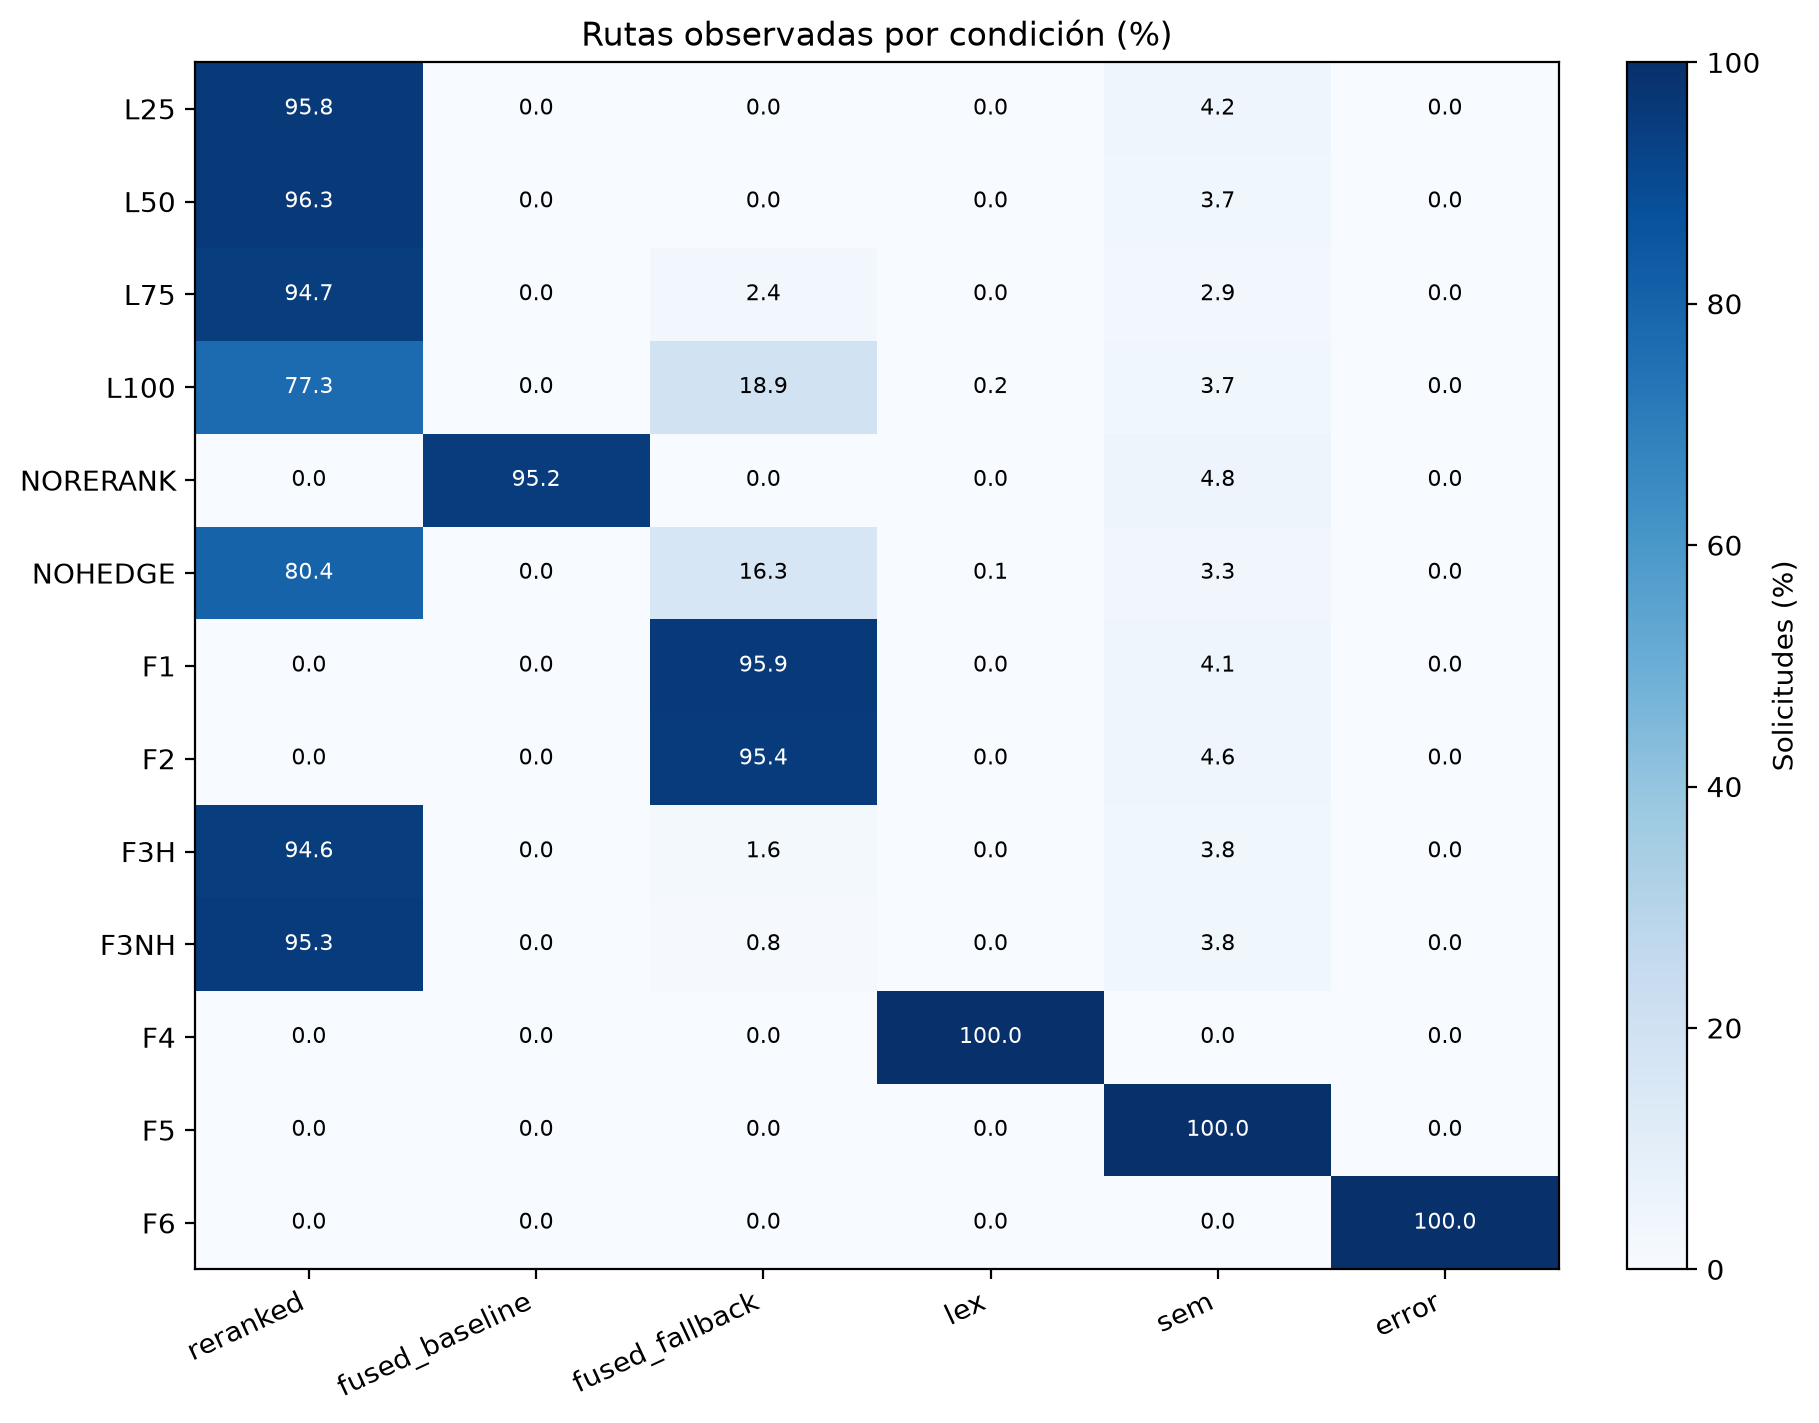

In [11]:
display(Image(filename=str(ROOT/'figs'/'K6_matriz_rutas_trec-covid.png')))

La matriz distingue omitir el reranker a propósito de invocarlo y usar respaldo. Un SLO cumplido no implica ejecución de la ruta completa en todas las solicitudes.

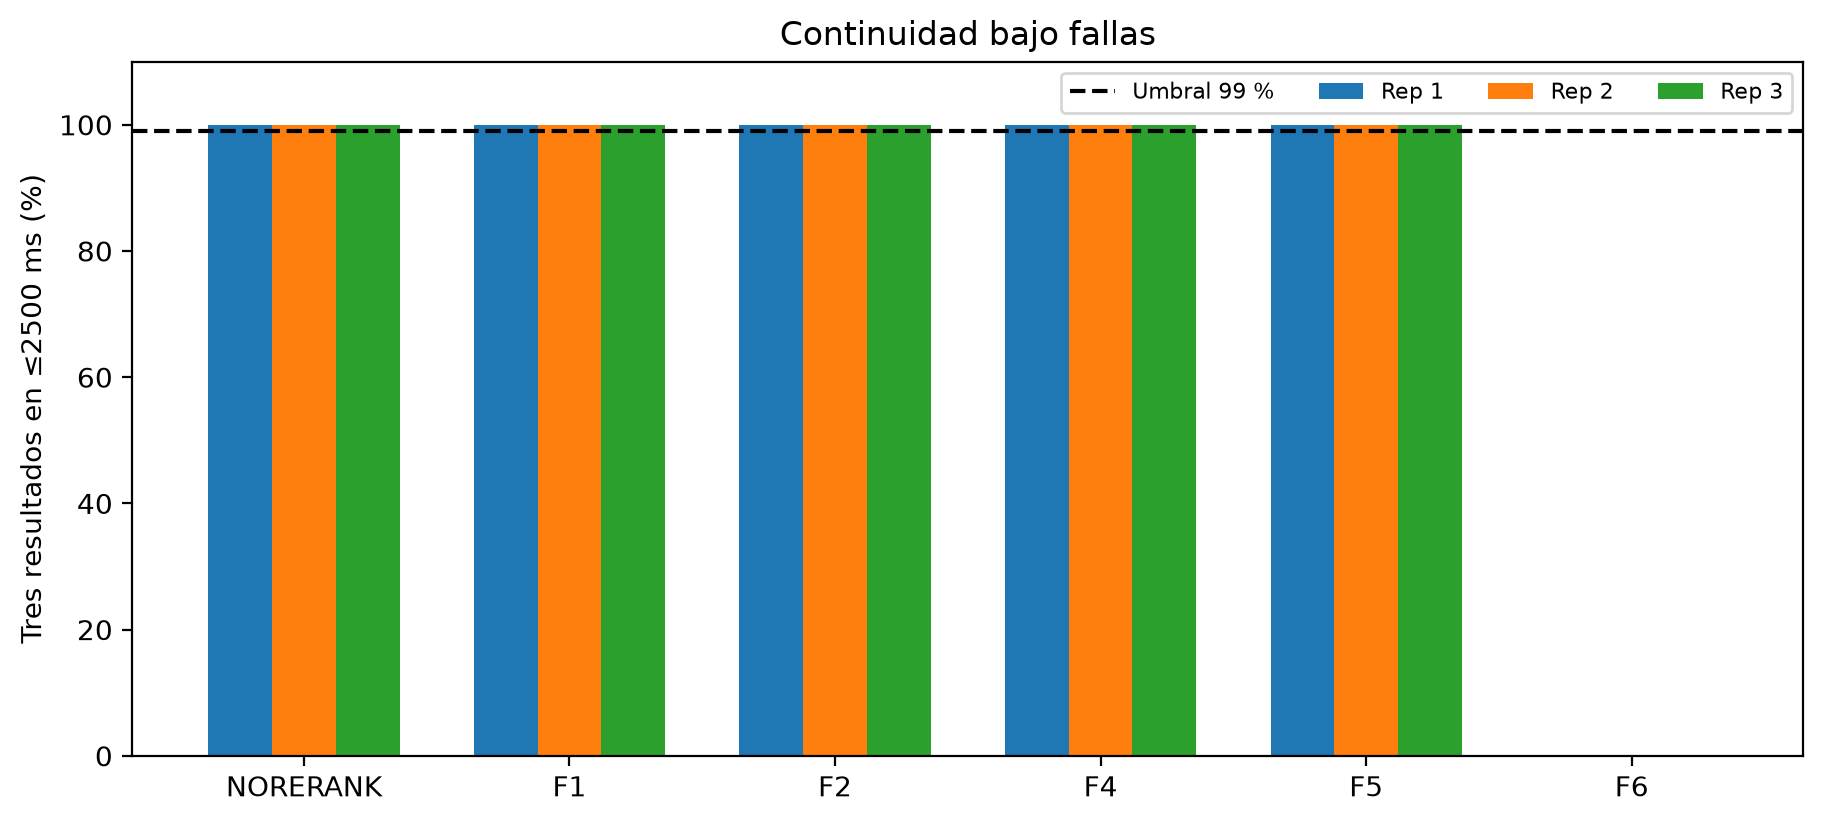

In [12]:
display(Image(filename=str(ROOT/'figs'/'K7_continuidad_trec-covid.png')))

F1 y F2 son las pruebas de continuidad ante error o lentitud del reranker. En F6 fallan las dos rutas y se espera error controlado, no continuidad.

## Comparación pareada del hedging

Se verifican IDs y horarios iguales y la asignación de demoras por semilla 42 e índice. Las banderas observadas se reportan aparte: si una consulta usa respaldo antes de rerank, no recibe la demora asignada a esa etapa. La reducción se define p99 sin hedge menos p99 con hedge; un valor negativo indica empeoramiento. Las diferencias entre tres p99 son descriptivas y no equivalen a un ensayo con solicitudes independientes.

,rep,p99_H_ms,p99_NH_ms,p99_reduction_ms,dup_H_pct,paired_inputs_equal,planned_delays_count,observed_delay_mismatches,observed_delay_mismatches_postwarm,observed_delays_equal
0,1,1319.865,1232.879,-86.986,9.729,True,48,2,2,False
1,2,1490.621,1324.644,-165.977,9.725,True,42,1,1,False
2,3,1411.136,1484.724,73.588,9.711,True,53,1,1,False


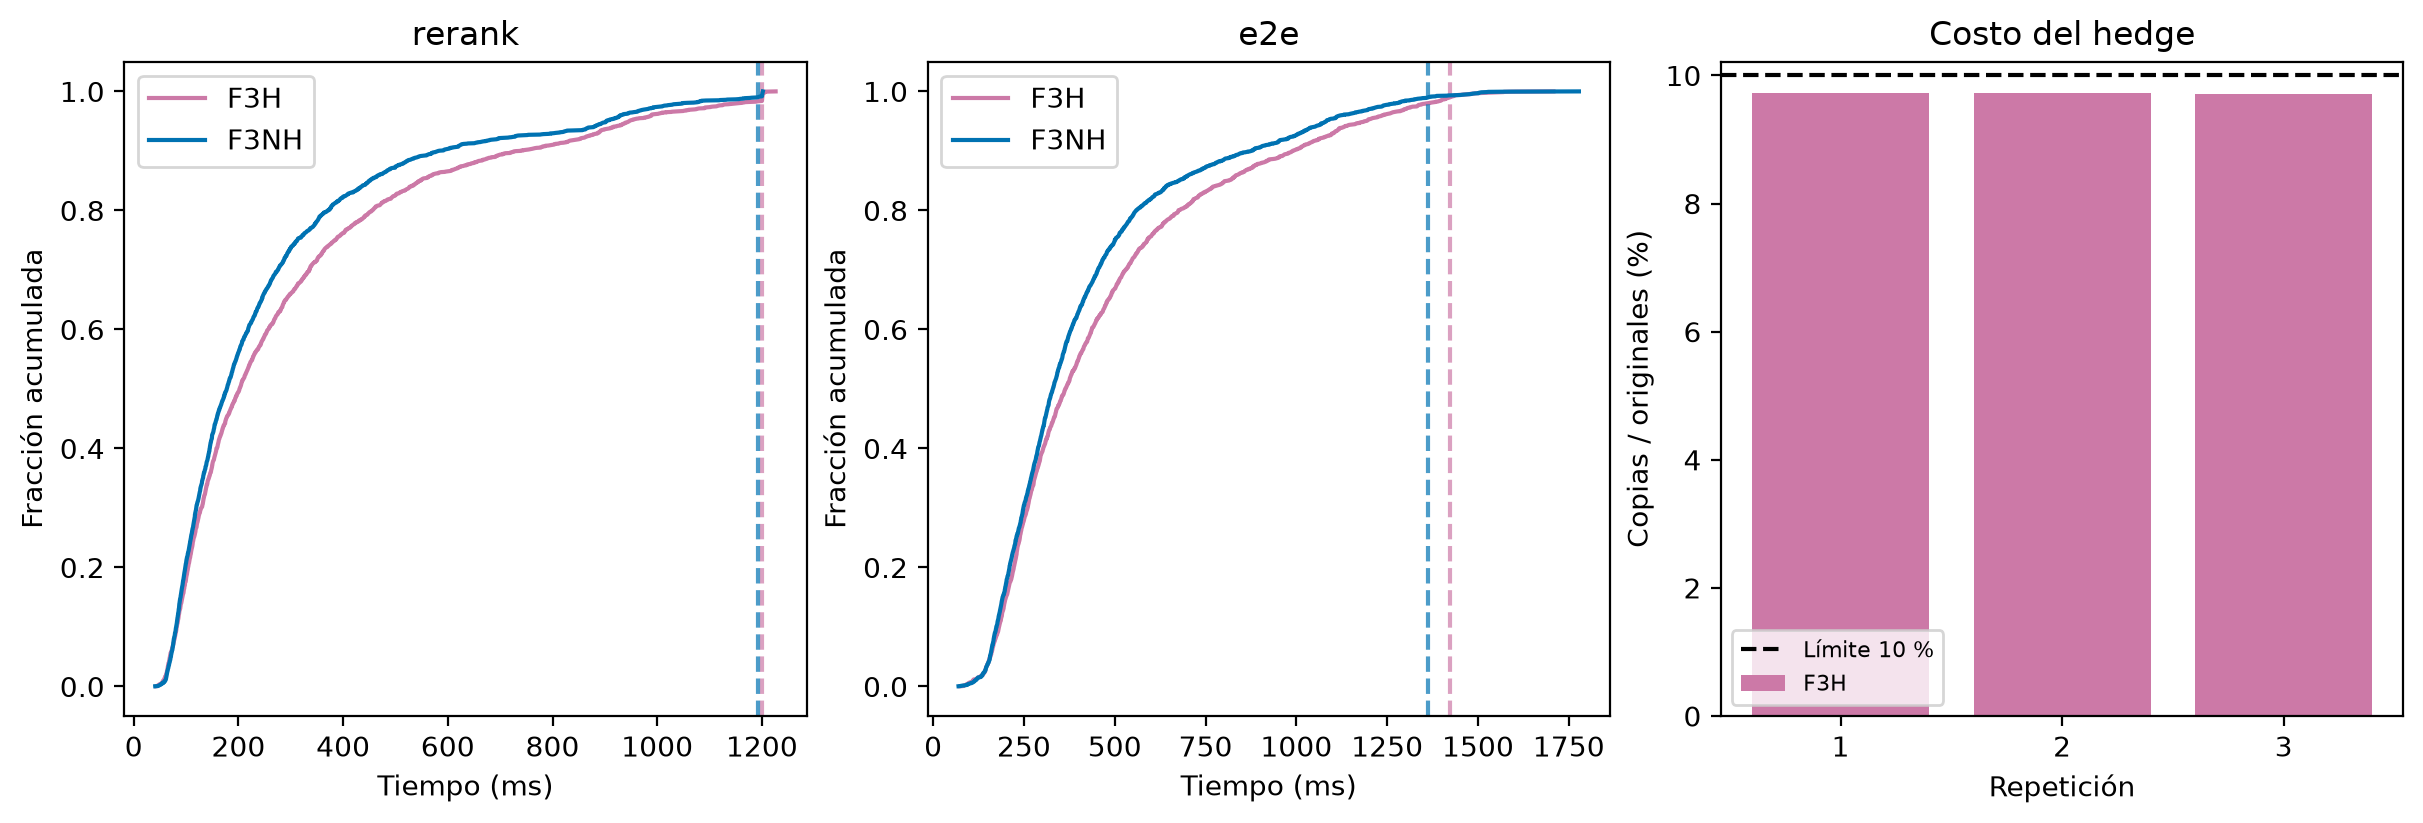

In [13]:
display(run.hedging())
display(Image(filename=str(ROOT/'figs'/'K8_hedging_trec-covid.png')))

La reducción NH−H del p99 extremo a extremo por repetición es [-87.0, -166.0, 73.6] ms. La CDF de etapa incluye solo invocaciones; la CDF extremo a extremo incluye toda respuesta válida. IDs y llegadas coinciden; las demoras efectivas difieren en [2, 1, 1] solicitudes poscalentamiento por repetición por rutas previas. No es una estimación causal aislada del hedge.

## Fitness y relación con el Trabajo 1

Se comprueban p99 bajo carga, continuidad mínima en F1/F2 y duplicadas máximas en L25–L100/F3H. La mejora de P@3 se responde con la evaluación offline ya ejecutada: no se deriva de la continuidad. La misma lista de respaldo puede tener distinta calidad y distinto costo temporal.

,rep,max_load_p99_ms,fitness_i,min_F1F2_continuity_pct,fitness_iii,max_dup_pct,fitness_iv
0,1,1745.818,True,100.0,True,9.912,True
1,2,2067.905,True,100.0,True,9.915,True
2,3,1728.866,True,100.0,True,9.904,True


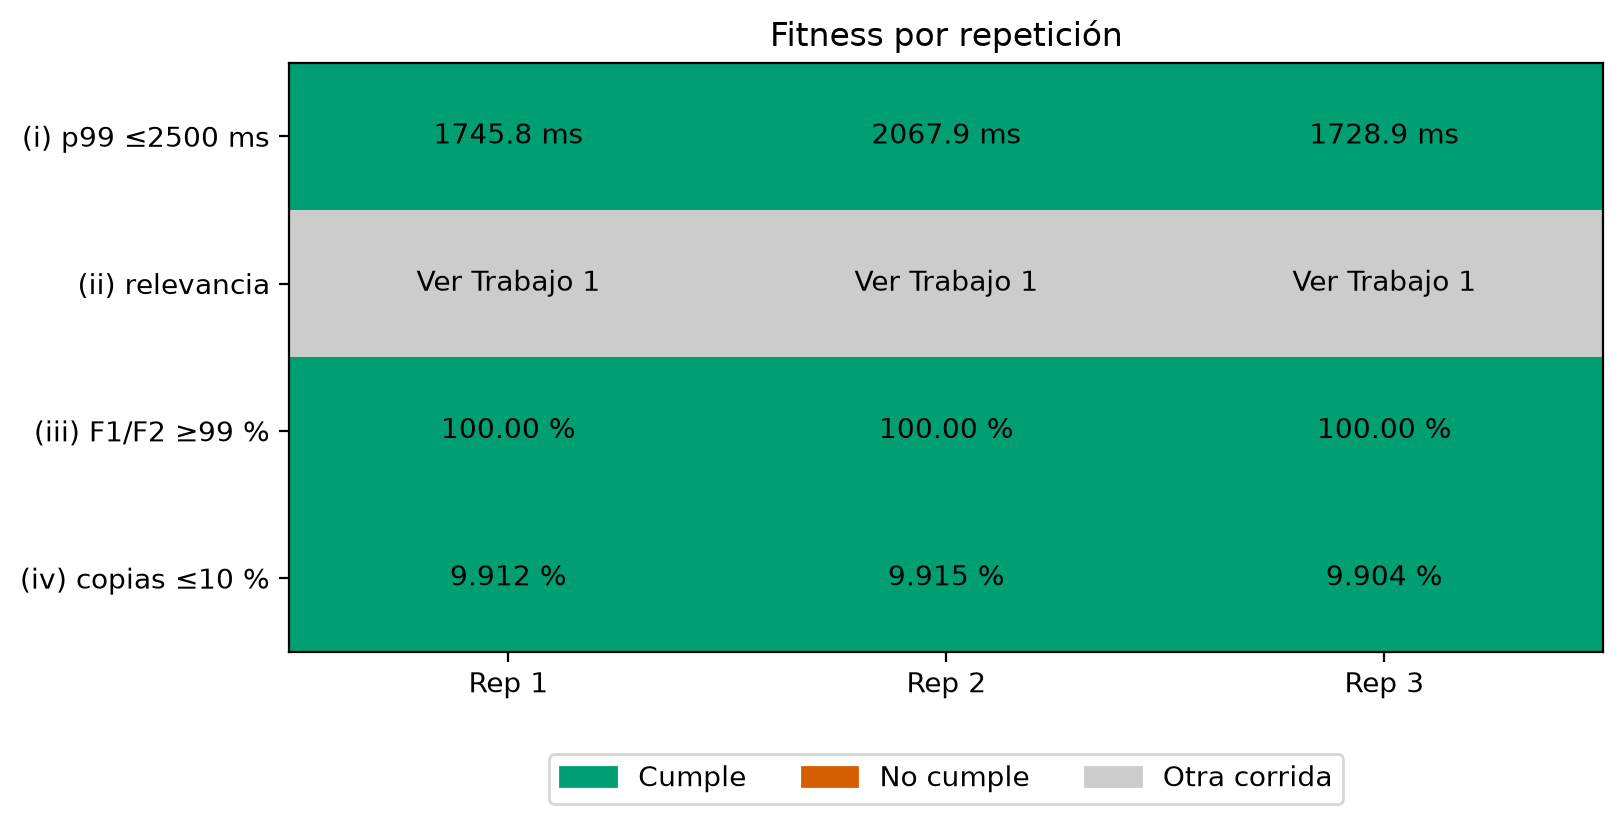

In [14]:
display(run.fitness())
display(Image(filename=str(ROOT/'figs'/'K9_fitness_trec-covid.png')))

Las fitness temporales se calculan por repetición. La relevancia se evalúa en el Trabajo 1: no se convierte una prueba de continuidad en una prueba de mejora de P@3.

## FiQA y TREC-COVID en ds001

La siguiente tabla mantiene los resultados de cada dataset separados e incluye C y QPS absolutos. No se atribuye una diferencia a la GPU porque ambos usan A6000, ni se atribuye causalmente al dataset sin controlar la contención compartida.

In [15]:
reference=pd.read_csv(ROOT/'reference_fiqa_summary.csv')
refmeta=json.loads((ROOT/'reference_fiqa_run_meta.json').read_text())
rows=[]
for ds,table,C in [('fiqa',reference,refmeta['calibration_json']['C_qps']),('trec-covid',run.summary,run.cal['C_qps'])]:
    for c in ['L100','NORERANK','F1','F2','F3H','F3NH']:
        g=table[table.condition==c]
        rows.append(dict(dataset=ds,condition=c,C_qps=C if ds=='fiqa' else None,external_load_reference_qps=8,offered_qps=g.offered_qps.iloc[0],p99_median_ms=g.p99_ms.median(),p99_min_ms=g.p99_ms.min(),p99_max_ms=g.p99_ms.max(),continuity_min_pct=g.continuity_pct.min()))
display(pd.DataFrame(rows))

,dataset,condition,C_qps,external_load_reference_qps,offered_qps,p99_median_ms,p99_min_ms,p99_max_ms,continuity_min_pct
0,fiqa,L100,8.0,8,8.0,1483.018,1417.606,1504.033,100.000
1,fiqa,NORERANK,8.0,8,8.0,88.341,84.536,89.937,100.000
2,fiqa,F1,8.0,8,6.0,82.364,80.068,82.994,100.000
3,fiqa,F2,8.0,8,6.0,1281.844,1281.626,1289.665,100.000
4,fiqa,F3H,8.0,8,6.0,1091.109,1070.420,1211.845,100.000
5,fiqa,F3NH,8.0,8,6.0,1061.083,983.053,1262.846,100.000
6,trec-covid,L100,NaN,8,8.0,1745.818,1728.866,2067.905,99.917
7,trec-covid,NORERANK,NaN,8,8.0,297.188,251.153,315.829,100.000
8,trec-covid,F1,NaN,8,6.0,233.912,223.089,283.552,100.000
9,trec-covid,F2,NaN,8,6.0,1438.326,1426.781,1439.867,100.000


## Interpretación y límites

El sistema es un proceso con hilos y dos réplicas en una GPU compartida; las fallas son inyectadas y no representan máquinas físicamente independientes. Las consultas test se recorren cíclicamente: más solicitudes no equivalen a nuevas consultas independientes. Las comparaciones estadísticas de relevancia y los análisis de invocación no sustituyen mediciones temporales de esas variantes.

In [16]:
a=run.aggregate().set_index('condition')
h=run.hedging()
f=run.fitness()
print('p99 L100 mediana [mínimo,máximo]:',a.loc['L100',['p99_ms_median','p99_ms_min','p99_ms_max']].to_dict())
print('Reducciones p99 por hedge:',h.p99_reduction_ms.tolist())
print('Repeticiones que cumplen i, iii, iv:',f[['fitness_i','fitness_iii','fitness_iv']].sum().to_dict())
print('Fuente exacta del benchmark:',run.meta['script_sha256'])
print('Conclusiones limitadas a este montaje y la contención registrada.')

p99 L100 mediana [mínimo,máximo]: {'p99_ms_median': 1745.818, 'p99_ms_min': 1728.866, 'p99_ms_max': 2067.905}
Reducciones p99 por hedge: [-86.9860000000001, -165.9770000000001, 73.58799999999997]
Repeticiones que cumplen i, iii, iv: {'fitness_i': 3, 'fitness_iii': 3, 'fitness_iv': 3}
Fuente exacta del benchmark: bb027763a577074373d5c1909467fbac67f8b5484d37696b29e1f697f02f22b7
Conclusiones limitadas a este montaje y la contención registrada.


## Verificación final y archivos

Los percentiles, continuidad y porcentaje de duplicadas se contrastan contra cada archivo de solicitudes después del descarte. El intento de capacidad, el piloto y el ensayo a carga fija permanecen separados. Este notebook solo relee resultados: no repite inferencia. El campo C_qps=8 del adaptador de entrada solo escala cargas y NO valida la capacidad de TREC.

In [17]:
verification=run.verify()
assert verification['passed']
assert len(list((ROOT/'figs').glob('*.png')))==9
print('39 condiciones verificadas; tres pares de IDs y horarios iguales, exposición a demoras auditada; nueve figuras.')

39 condiciones verificadas; tres pares de IDs y horarios iguales, exposición a demoras auditada; nueve figuras.
